In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input , Dense
import pandas as pd
import numpy as np


In [7]:
data = pd.read_csv(r'Housing.csv')
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [18]:
X = data.drop(columns = ["price"])
y = data[["price"]]

In [19]:
yes_no_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for column in yes_no_columns:
    data[column] = data[column].map({"no":0 , "yes" : 1})

# Convert furnishing status
data["furnishingstatus"] = data["furnishingstatus"].map({
    "unfurnished": 0,
    "semi-furnished": 1,
    "furnished": 2
})

In [20]:
X_train , X_test , y_train , y_test = train_test_split(X, y ,test_size= 0.2, random_state = 43)

In [21]:
X_train.shape

(436, 12)

In [24]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scale = scaler_X.fit_transform(X_train)
X_test_scale = scaler_X.transform(X_test)

y_train_scale = scaler_y.fit_transform(y_train)
y_test_scale = scaler_y.transform(y_test)


In [27]:
model = Sequential(
    [
        Input(shape = (X_train.shape[1] ,)),
        Dense(10 , activation = "relu"),
        Dense(5, activation = "relu"),
        Dense(1)
    ]
)

model.compile(
    optimizer = "adam",
    loss  = "mean_squared_error"
)

history = model.fit(
    X_train_scale , y_train_scale , epochs = 100 , batch_size = 32 , verbose = 1
)

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1693
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0215 
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9327 
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8700 
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8101 
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7596 
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7118 
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6654 
Epoch 9/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6236 
Epoch 10/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5820 
Epoch 11/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5466 
Epoch 12/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5139 
Epoch 13/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4870  
Epoch 14/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4593 
Epoch 15/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - los

In [30]:

predictions_scale = model.predict(
    X_test_scale,
    verbose=0
)

In [31]:
predictions_scale[:5]

array([[-0.49261627],
       [-0.4820707 ],
       [-0.3346266 ],
       [-0.931179  ],
       [-1.0572991 ]], dtype=float32)

In [32]:
prediction = scaler_y.inverse_transform(predictions_scale)

In [33]:
prediction[:5]

array([[3901033.2],
       [3920680.5],
       [4195381. ],
       [3083955. ],
       [2848983. ]], dtype=float32)

In [34]:
y_test[:5]

,price
392,3500000
349,3780000
476,2940000
480,2940000
542,1750000


In [ ]:
from  sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input , Dense
import pandas as pd
import numpy as np


In [ ]:
data = load_iris()
X = data.data
y = data.target
X.shape , y.shape

print("Input names:")
print(data.feature_names)

print("\nFlower names:")
print(data.target_names)
import pandas as pd
df = pd.DataFrame(
    X , 
    columns = data.feature_names
)
# 3. Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
# 4. Scale the inputs

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = Sequential([
    Input(shape = (X_train.shape[1],)),
    Dense(10 ),
    Dense(3 , activation = 'softmax')
])
model.compile(optimizer = 'adam', loss = "sparse_categorical_crossentropy" , metrics = ["accuracy"])
model.fit(
X_train , y_train,epochs = 50
)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [48]:
X_train.shape

(120, 4)

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0333 - loss: 1.8199  
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0333 - loss: 1.7496 
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0333 - loss: 1.6851 
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0333 - loss: 1.6213
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0417 - loss: 1.5627    
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0417 - loss: 1.5040     
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0500 - loss: 1.4472
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0833 - loss: 1.3938
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0917 - loss: 1.3446 
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1500 - loss: 1.2968 
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1833 - loss: 1.2511 
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2250 - loss:

In [31]:
loss , accuracy = model.evaluate(
        X_test , y_test
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.8667 - loss: 0.5125


In [32]:
flower = [[5.1 , 4.3 , 1.4 , 0.2]]
flower = scaler.transform(flower)
prob = model.predict(flower)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


In [33]:
prob

array([[0.96983206, 0.01586942, 0.0142986 ]], dtype=float32)

In [38]:
flower = np.argmax(prob)
flower

0

In [65]:
flower

0

In [41]:
iris.target_names[0]

'setosa'

In [67]:
iris.target_names[flower]

'setosa'

In [72]:

data = pd.DataFrame(
    X,
    columns =iris.feature_names
)
data


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [1]:
class_1 = 2.1
class_2 = 3.5
class_3 = 2.7

softmax_1 = class_1 / (class_1 + class_2 + class_3)
softmax_1

0.25301204819277107

In [2]:

softmax_2 = class_2 / (class_1 + class_2 + class_3)
softmax_2

0.4216867469879518

In [3]:

softmax_3 = class_3 / (class_1 + class_2 + class_3)
softmax_3

0.3253012048192771

In [5]:
total = softmax_1 +softmax_2+softmax_3
total

1.0

In [6]:
import numpy as np

In [8]:
yes = 2.1
no = 3.5

sigmoid =  1 / (1+np.exp(-yes))
sigmoid

0.8909031788043871

In [9]:

sigmoid =  1 / (1+np.exp(-no))
sigmoid

0.9706877692486436

In [1]:
class_a = 2.3
class_b = 1.4
class_c = 1.2

softmax_a = class_a / (class_a + class_b + class_c)

softmax_a

0.46938775510204084

In [2]:

softmax_b = class_b / (class_a + class_b + class_c)

softmax_b

0.28571428571428575

In [3]:

softmax_c = class_c / (class_a + class_b + class_c)

softmax_c

0.2448979591836735

In [4]:
softmax_a + softmax_b + softmax_c

1.0

In [1]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten , Input , Dense
import numpy as np


In [2]:
(X_train,y_train) , (X_test,y_test) = mnist.load_data()

In [3]:
X_train.shape , X_test.shape , y_train.shape

((60000, 28, 28), (10000, 28, 28), (60000,))

In [4]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, '9')

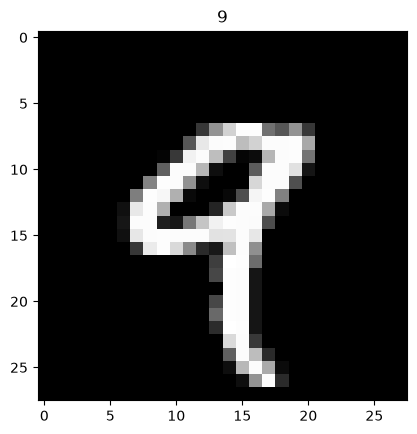

In [5]:
image = X_train[4]
label = y_train[4]

plt.imshow(image , cmap = "gray")
plt.title(label)

In [6]:
a  = np.array([22,44,33,55,66,77])
scale = a / 77
scale

array([0.28571429, 0.57142857, 0.42857143, 0.71428571, 0.85714286,
       1.        ])

In [8]:
X_train_scale = X_train / 255.0
X_test_scale = X_test / 255.0

In [10]:
model = Sequential([
    Input(shape= (28,28)),
    Flatten(),
    Dense(256),
    Dense(128),
    Dense(64),
    Dense(32),
    Dense(10 , activation = "softmax")
])

In [11]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [12]:
model.fit(X_train_scale , y_train ,epochs = 100,  batch_size = 32 , verbose = 1) 

Epoch 1/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 9ms/step - accuracy: 0.8827 - loss: 0.4029
Epoch 2/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.9022 - loss: 0.3427
Epoch 3/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9063 - loss: 0.3281
Epoch 4/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9096 - loss: 0.3145
Epoch 5/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9128 - loss: 0.3073
Epoch 6/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9149 - loss: 0.3004
Epoch 7/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 22ms/step - accuracy: 0.9163 - loss: 0.2954
Epoch 8/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 17ms/step - accuracy: 0.9184 - loss: 0.2916
Epoch 9/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.9192 - loss: 0.2881
Epoch 10/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9203 - loss: 0.2855
Epoch 11/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9198 - loss: 0.2838
Epo

In [20]:
loss , accuracy = model.evaluate(X_test , y_test)
print(f"Accuracy: {accuracy*100}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8632 - loss: 86.3095
Accuracy: 86.32000088691711%


In [25]:
prediction = model.predict(X_test[1].reshape(1,28,28))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step


In [27]:
prediction

array([[0., 0., 1., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [28]:
np.argmax(prediction)


2

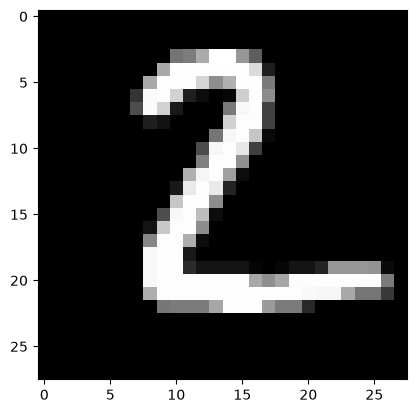

In [26]:
plt.imshow(X_test[1] , cmap = "gray")

In [30]:
prediction = model.predict(X_test[7].reshape(1,28,28))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


In [31]:
np.argmax(prediction)

9

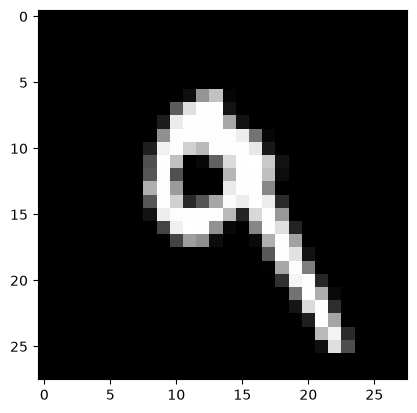

In [32]:
plt.imshow(X_test[7] , cmap = "gray")